# Import

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Teorema Aproximación Universal

## \begin{equation}
f(x) = \sin(x)
\end{equation}


In [2]:
# Generación de datos de entrenamiento
x_train = np.linspace(-np.pi, np.pi, 1000)
y_train = np.sin(x_train)

# Redimensionamos x_train para que sea un array de forma (n_samples, 1)
x_train = x_train.reshape(-1, 1)
y_train = y_train.reshape(-1, 1)

# Creación del modelo de red neuronal con una sola capa oculta
model = Sequential([
    # Capa oculta con 20 neuronas y función de activación no lineal (sigmoide en este ejemplo)
    Dense(20, activation='sigmoid', input_shape=(1,)),
    # Capa de salida (una neurona, sin activación para regresión)
    Dense(1)
])

# Compilación del modelo especificando optimizador y función de pérdida
model.compile(optimizer='adam', loss='mse')

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [3]:
# Entrenamiento de la red neuronal
model.fit(x_train, y_train, epochs=500, verbose=0)

# Evaluación
x_test = np.linspace(-np.pi, np.pi, 1000).reshape(-1, 1)
y_pred = model.predict(x_test)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


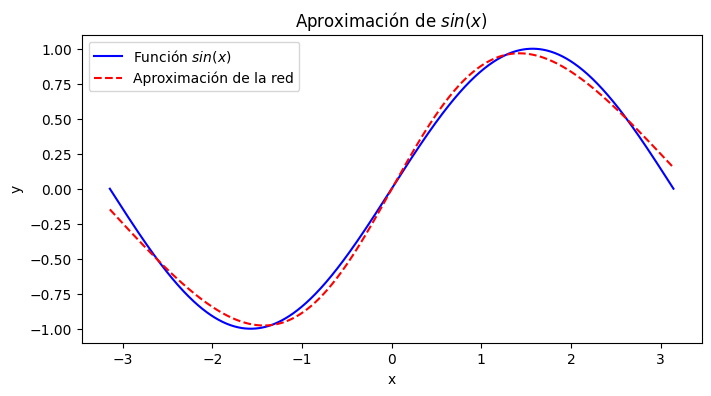

In [6]:
# Visualización
plt.figure(figsize=(8, 4))
plt.plot(x_test, np.sin(x_test), label='Función $sin(x)$', color='blue')
plt.plot(x_test, y_pred, label='Aproximación de la red', color='red', linestyle='--')
plt.title("Aproximación de $sin(x)$")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


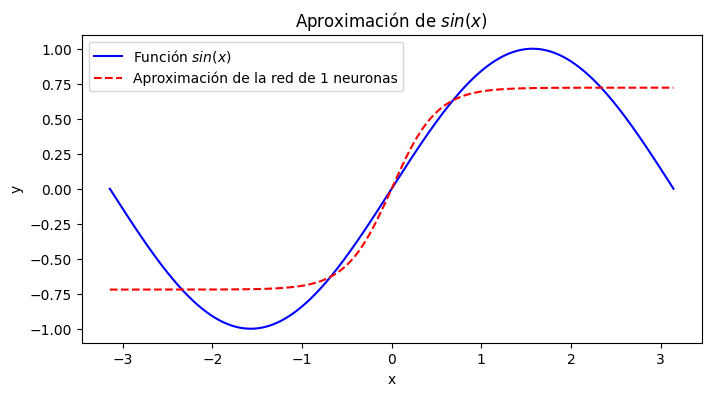

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


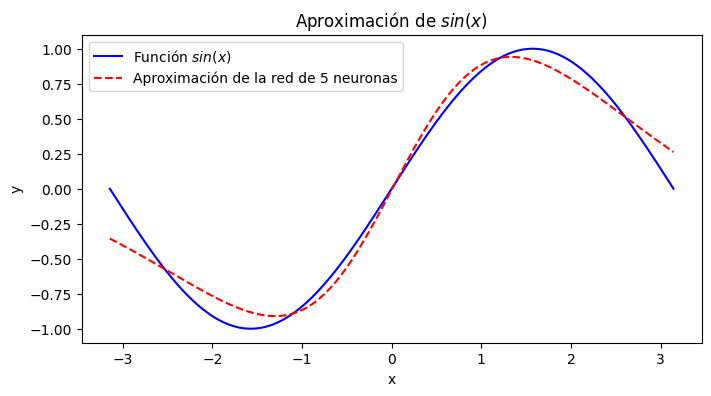

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


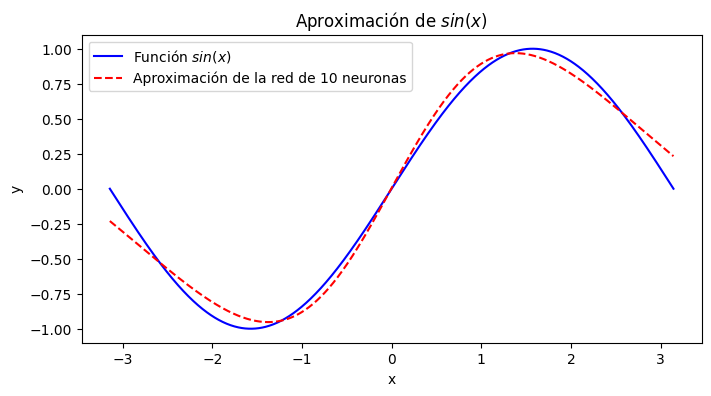

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


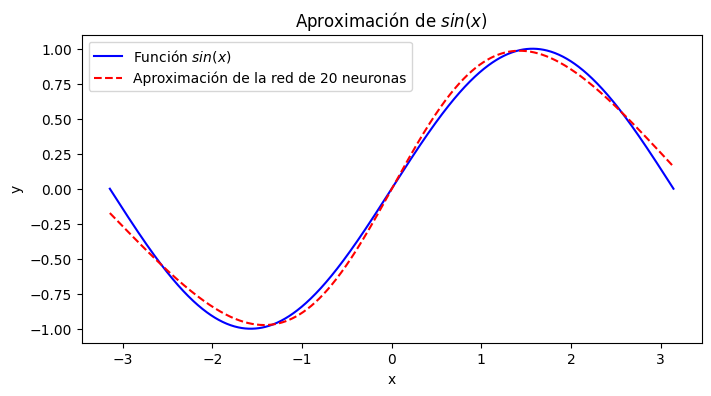

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


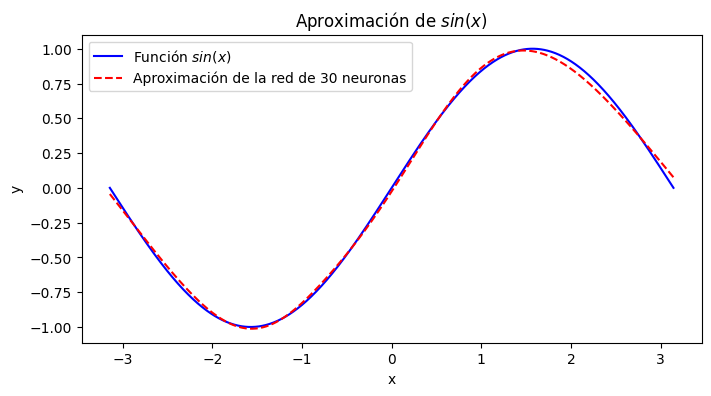

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


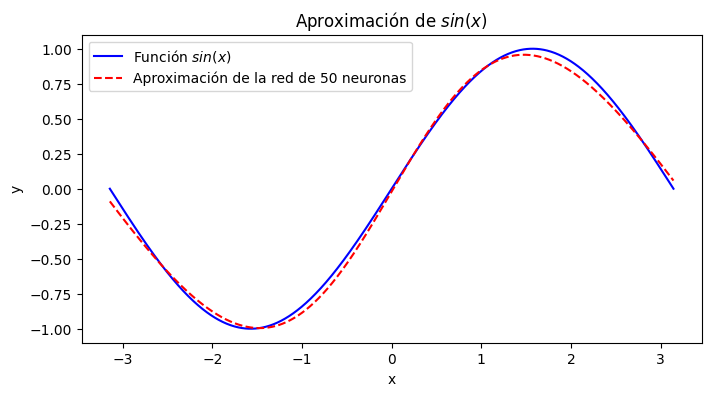

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


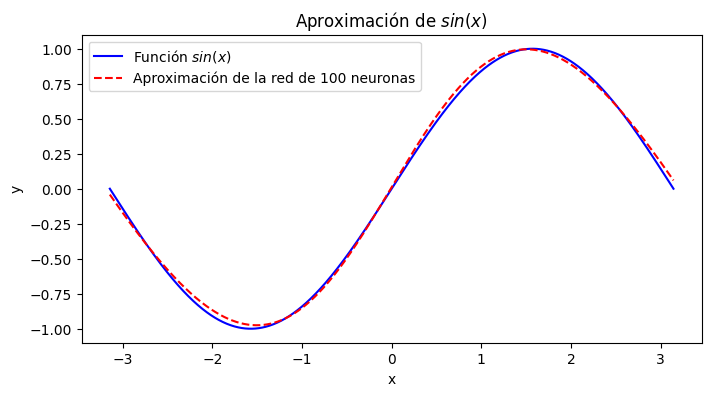

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


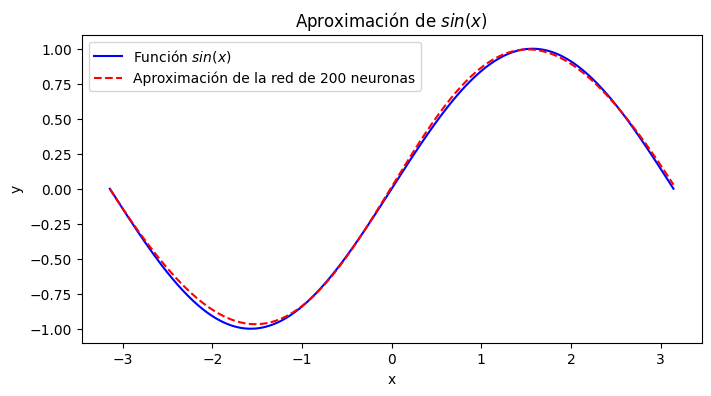

In [7]:
for i in [1, 5, 10, 20, 30, 50, 100, 200]:
    model = Sequential([
        Dense(i, activation='sigmoid', input_shape=(1,)),
        Dense(1)
    ])

    model.compile(optimizer='adam', loss='mse')

    model.fit(x_train, y_train, epochs=500, verbose=0)

    x_test = np.linspace(-np.pi, np.pi, 1000).reshape(-1, 1)
    y_pred = model.predict(x_test)

    plt.figure(figsize=(8, 4))
    plt.plot(x_test, np.sin(x_test), label='Función $sin(x)$', color='blue')
    plt.plot(x_test, y_pred, label=f'Aproximación de la red de {i} neuronas', color='red', linestyle='--')
    plt.title("Aproximación de $sin(x)$")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.show()

## \begin{equation}
f(x) = \sin(3x) \cdot e^{-x^2} + 0.5 \cdot \cos(5x)
\end{equation}


In [8]:
# Generación de datos
x_train = np.linspace(-3, 3, 1000).reshape(-1, 1)
y_train = np.sin(3 * x_train) * np.exp(-x_train**2) + 0.5 * np.cos(5 * x_train)

In [9]:
# Construcción del modelo
model = Sequential([
    Dense(50, activation='tanh', input_shape=(1,)),  # Capa oculta con 50 neuronas y activación tanh
    Dense(1)  # Capa de salida
])

# Compilación
model.compile(optimizer='adam', loss='mse')

In [10]:
# Entrenamiento
model.fit(x_train, y_train, epochs=1000, verbose=0)

# Evaluación
x_test = np.linspace(-3, 3, 1000).reshape(-1, 1)
y_true = np.sin(3 * x_test) * np.exp(-x_test**2) + 0.5 * np.cos(5 * x_test)
y_pred = model.predict(x_test)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


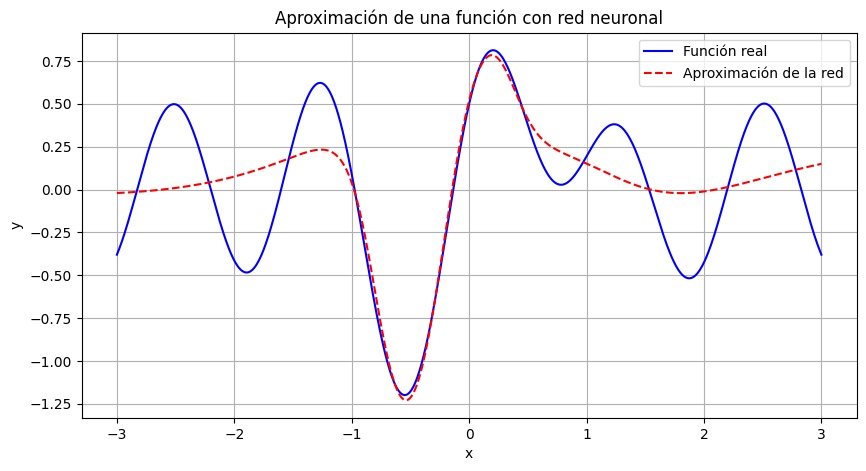

In [11]:
# Visualización
plt.figure(figsize=(10, 5))
plt.plot(x_test, y_true, label='Función real', color='blue')
plt.plot(x_test, y_pred, label='Aproximación de la red', color='red', linestyle='--')
plt.title("Aproximación de una función con red neuronal")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()